# Chapter 7 companion notebook: choosing a distributed training strategy

This notebook reproduces the quantitative results in Chapter 7. It has two kinds
of cell:

- **Analytical cells** run here and now on CPU. They import the same modules the
  chapter ships (`mem_wall`, `comm_cost`, `bubble`, `tp_mlp`, `moe_routing`), so the
  tables and figures you see are computed live, not pasted in.
- **Measured multi-GPU cells** report throughput and peak memory measured on two
  NVIDIA A10G GPUs through the launch scripts `ddp_train.py` and `fsdp_train.py`.
  A single-GPU laptop cannot run these, so the numbers are embedded as data and
  labeled *measured on 2x A10G*. Each such cell gives the exact `torchrun` command
  that produced it, so you can reproduce it on your own multi-GPU node.

Everything modeled is labeled modeled; everything measured is labeled measured, and
the gap between the two (the point of the FSDP section) is shown explicitly.

In [1]:
import sys, os
# Import the chapter's own modules so the notebook computes, rather than restates.
sys.path.insert(0, os.path.dirname(os.path.abspath("__file__")) if "__file__" in dir() else ".")

import numpy as np
import matplotlib.pyplot as plt

import mem_wall, comm_cost, bubble, tp_mlp, moe_routing

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.autolayout": True})
print("modules loaded:", [m.__name__ for m in (mem_wall, comm_cost, bubble, tp_mlp, moe_routing)])

modules loaded: ['mem_wall', 'comm_cost', 'bubble', 'tp_mlp', 'moe_routing']


## The memory wall: why one GPU runs out

Model-state memory is an accounting model, not a universal constant. "Bytes per
parameter" is set by the precision of the parameter copy, the gradient buffer, the
fp32 master weights, and the optimizer states. The mixed-precision Adam baseline
the chapter uses works out to 16 bytes per parameter; other regimes move the number
up or down. The table below is computed live from `mem_wall.REGIMES`.

In [2]:
rows = mem_wall.build_table(sizes_billion=(1, 7, 70), gpu_gb=80, shard_count=8)
print(f"{'regime':<44}{'B/param':>8}{'params':>8}{'repl GB':>10}"
      f"{'fits 1x80GB?':>13}{'8-way GB':>10}{'min 80GB GPUs':>15}")
print("-" * 108)
for r in rows:
    print(f"{r['regime']:<44}{r['bytes_per_param']:>8.0f}{r['params_billion']:>7}B"
          f"{r['replicated_gb']:>10.1f}{('yes' if r['fits_one_80gb_replicated'] else 'no'):>13}"
          f"{r['per_gpu_gb_8way']:>10.1f}{r['min_80gb_gpus_linear_shard']:>15}")
# The chapter's worked example: a 7B model in mixed-precision Adam.
print(f"\n7B @ 16 B/param: {mem_wall.model_state_gb(7,16):.0f} GB replicated, "
      f"{mem_wall.model_state_gb(7,16,8):.0f} GB across an 8-way shard (modeled floor).")

regime                                       B/param  params   repl GB fits 1x80GB?  8-way GB  min 80GB GPUs
------------------------------------------------------------------------------------------------------------
Mixed-precision Adam baseline                     16      1B      16.0          yes       2.0              1
Mixed-precision Adam baseline                     16      7B     112.0           no      14.0              2
Mixed-precision Adam baseline                     16     70B    1120.0           no     140.0             14
BF16 params, low-precision optimizer state        12      1B      12.0          yes       1.5              1
BF16 params, low-precision optimizer state        12      7B      84.0           no      10.5              2
BF16 params, low-precision optimizer state        12     70B     840.0           no     105.0             11
Full FP32 Adam                                    16      1B      16.0          yes       2.0              1
Full FP32 Adam     

The stacked bars below break the 16 bytes per parameter into its four occupants for
the mixed-precision Adam baseline, and show how the per-GPU model state falls as we
shard it linearly (the ZeRO-3 / FSDP idea). This is the modeled steady-state floor;
the FSDP section later measures how far above it the real peak sits.

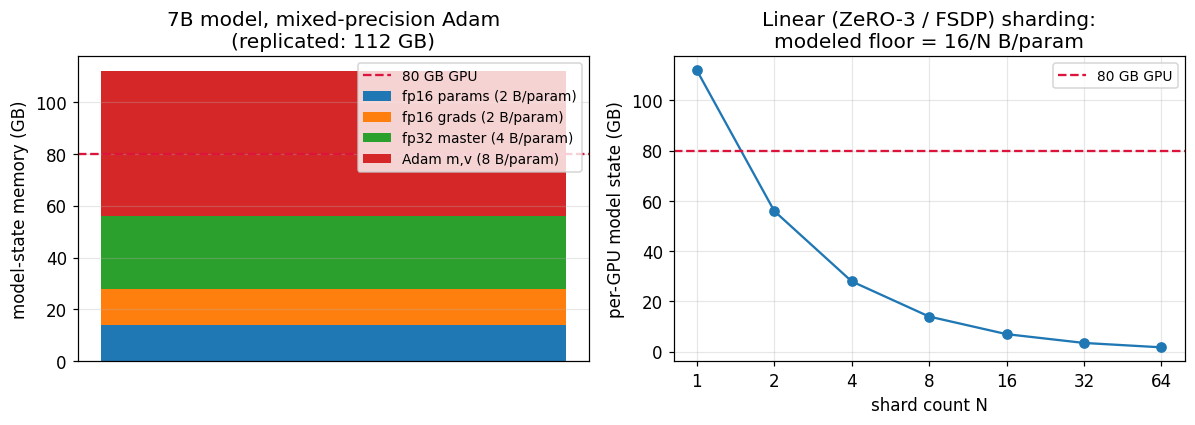

In [3]:
baseline = mem_wall.REGIMES[0]  # Mixed-precision Adam baseline
params_b = 7
occupants = [("fp16 params", baseline.param_bytes), ("fp16 grads", baseline.grad_bytes),
             ("fp32 master", baseline.master_bytes), ("Adam m,v", baseline.optim_bytes)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Left: the 16 B/param decomposition for a 7B model, replicated on one GPU.
bottom = 0
for name, b in occupants:
    gb = params_b * b  # GB for a 7B model (b bytes/param * 7e9 / 1e9)
    ax1.bar(0, gb, bottom=bottom, label=f"{name} ({b} B/param)")
    bottom += gb
ax1.axhline(80, ls="--", color="crimson", label="80 GB GPU")
ax1.set_xticks([]); ax1.set_ylabel("model-state memory (GB)")
ax1.set_title(f"{params_b}B model, mixed-precision Adam\n(replicated: {bottom:.0f} GB)")
ax1.legend(fontsize=9, loc="upper right")

# Right: per-GPU model state vs shard count (linear sharding).
shards = np.array([1, 2, 4, 8, 16, 32, 64])
per_gpu = [mem_wall.model_state_gb(params_b, baseline.bytes_per_param, s) for s in shards]
ax2.plot(shards, per_gpu, "o-")
ax2.axhline(80, ls="--", color="crimson", label="80 GB GPU")
ax2.set_xscale("log", base=2); ax2.set_xticks(shards); ax2.set_xticklabels(shards)
ax2.set_xlabel("shard count N"); ax2.set_ylabel("per-GPU model state (GB)")
ax2.set_title("Linear (ZeRO-3 / FSDP) sharding:\nmodeled floor = 16/N B/param")
ax2.legend(fontsize=9)
plt.show()

## Communication cost: ring all-reduce versus a parameter server

The ring all-reduce moves `2N(P-1)/P` bytes per rank, approaching `2N` and staying
essentially flat as the world size `P` grows. A naive parameter server funnels
`2N(P-1)` bytes through one node, growing linearly with `P`. The ratio is exactly
`P`, so the server moves ten times the ring's per-rank volume at `P = 10`. The
alpha-beta time model also shows the ring's latency term growing with `P` even as
its volume term saturates: bandwidth-optimal is not the same as latency-optimal.

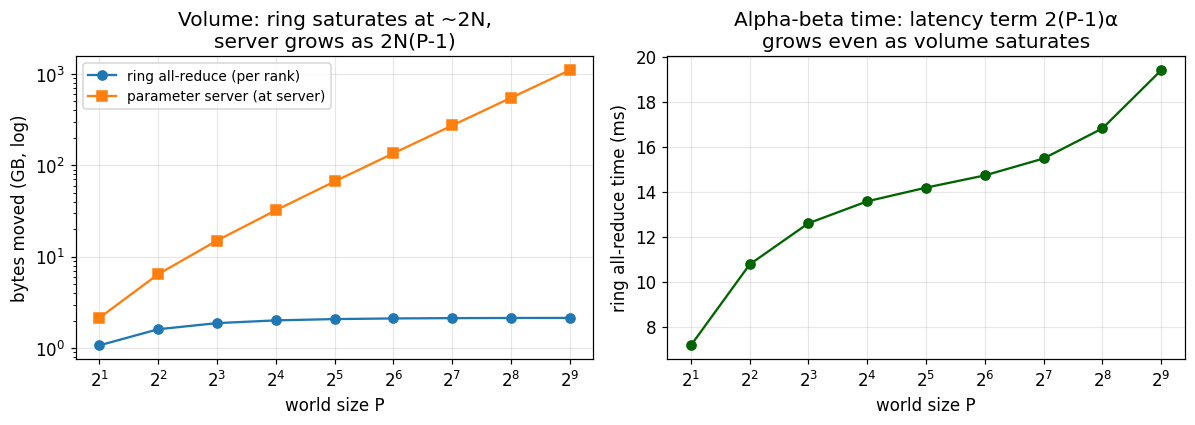

server/ring ratio at P=10 is exactly 10 (= P).


In [4]:
gib = 1024 ** 3
n_bytes = 1.0 * gib          # 1 GiB gradient payload, as in Exercise 7.3
alpha_s, bw = 5e-6, 150e9    # illustrative small-message latency and per-link bandwidth

P = np.array([2, 4, 8, 16, 32, 64, 128, 256, 512])
ring = np.array([comm_cost.ring_allreduce_bytes_per_rank(n_bytes, p) for p in P]) / 1e9
server = np.array([comm_cost.param_server_bytes(n_bytes, p) for p in P]) / 1e9
t_ms = np.array([comm_cost.ring_allreduce_time(n_bytes, p, alpha_s, bw) for p in P]) * 1e3

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(P, ring, "o-", label="ring all-reduce (per rank)")
ax1.plot(P, server, "s-", label="parameter server (at server)")
ax1.set_xscale("log", base=2); ax1.set_yscale("log")
ax1.set_xlabel("world size P"); ax1.set_ylabel("bytes moved (GB, log)")
ax1.set_title("Volume: ring saturates at ~2N,\nserver grows as 2N(P-1)")
ax1.legend(fontsize=9)

ax2.plot(P, t_ms, "o-", color="darkgreen")
ax2.set_xscale("log", base=2)
ax2.set_xlabel("world size P"); ax2.set_ylabel("ring all-reduce time (ms)")
ax2.set_title("Alpha-beta time: latency term 2(P-1)α\ngrows even as volume saturates")
plt.show()

print(f"server/ring ratio at P=10 is exactly {comm_cost.crossover_ratio(10):.0f} (= P).")

## Pipeline bubble fraction

A synchronous `P`-stage pipeline running `M` microbatches per step idles for a
fraction `(P-1)/(M+P-1)` of the step (total-time convention): fill at the start,
drain at the end. The bubble shrinks as `M` grows and never quite reaches zero for
finite `M`. Interleaved 1F1B with `v` virtual chunks per device cuts the constant
in front of `(P-1)`, giving roughly `(P-1)/(vM+P-1)`.

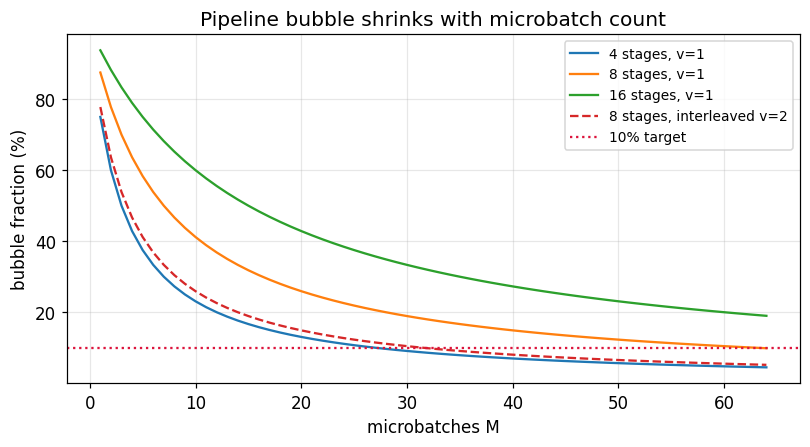

4-stage pipeline needs M >= 27 microbatches to hold the bubble below 10%.
8-stage pipeline needs M >= 63 microbatches to hold the bubble below 10%.
16-stage pipeline needs M >= 135 microbatches to hold the bubble below 10%.


In [5]:
M = np.arange(1, 65)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for p in (4, 8, 16):
    ax.plot(M, [bubble.bubble_fraction(p, m) * 100 for m in M], label=f"{p} stages, v=1")
ax.plot(M, [bubble.bubble_fraction_interleaved(8, m, v=2) * 100 for m in M],
        "--", label="8 stages, interleaved v=2")
ax.axhline(10, ls=":", color="crimson", label="10% target")
ax.set_xlabel("microbatches M"); ax.set_ylabel("bubble fraction (%)")
ax.set_title("Pipeline bubble shrinks with microbatch count")
ax.legend(fontsize=9)
plt.show()

for p in (4, 8, 16):
    print(f"{p}-stage pipeline needs M >= {bubble.microbatches_for_target(p, 0.10)} "
          f"microbatches to hold the bubble below 10%.")

## Tensor parallelism: the algebra checks out

Megatron splits the first MLP matrix by columns and the second by rows, then sums
the partial outputs with one all-reduce. The cell below verifies numerically (in
float64, on CPU) that this reproduces the single-GPU MLP exactly for 2-, 4-, and
8-way splits. One all-reduce in forward and one in backward per MLP sub-block; a
full transformer layer adds the attention sub-block's pair, giving the canonical
two-plus-two per layer.

In [6]:
import torch
torch.manual_seed(0)
x = torch.randn(8, 16, dtype=torch.float64)
A = torch.randn(16, 64, dtype=torch.float64)
B = torch.randn(64, 16, dtype=torch.float64)
ref = tp_mlp.single_gpu_mlp(x, A, B)
for tp in (2, 4, 8):
    out, n_ar = tp_mlp.tensor_parallel_mlp(x, A, B, tp=tp)
    err = (out - ref).abs().max().item()
    print(f"TP={tp}: max|tp - single| = {err:.2e}  match={torch.allclose(out, ref, atol=1e-10)}  "
          f"forward all-reduces={n_ar}")

TP=2: max|tp - single| = 4.26e-14  match=True  forward all-reduces=1
TP=4: max|tp - single| = 2.84e-14  match=True  forward all-reduces=1
TP=8: max|tp - single| = 2.84e-14  match=True  forward all-reduces=1


## Mixture-of-experts: routing imbalance and capacity dropping

A biased top-1 gate sends uneven token counts to the experts. A capacity-limited
router (GShard / Switch style) caps each expert at `capacity_factor * tokens /
experts` and drops the overflow. A higher capacity factor drops fewer tokens but
pads more. Dropless MoE (MegaBlocks) sidesteps the trade-off with block-sparse
GEMMs; auxiliary-loss-free balancing (DeepSeek-V3) flattens the counts instead.

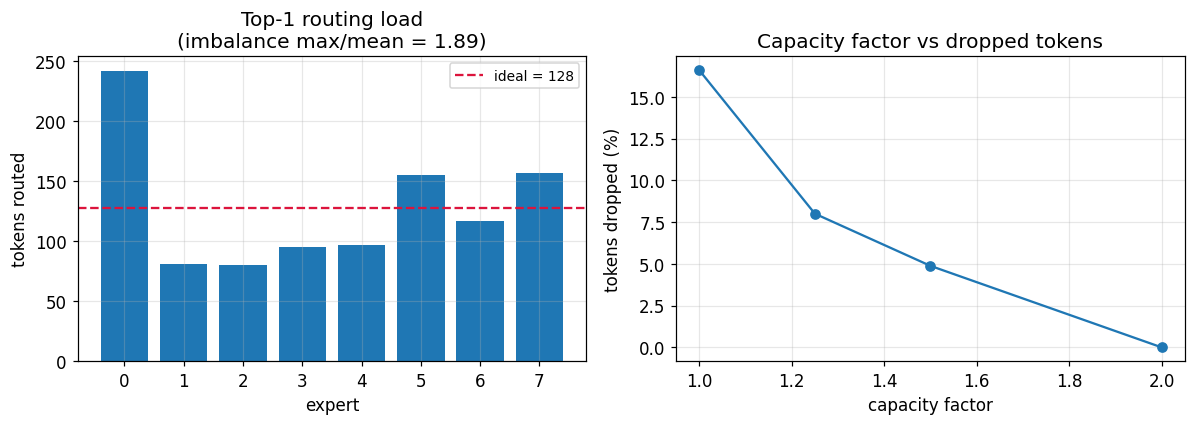

capacity_factor=1.00: 16.6% dropped
capacity_factor=1.25: 8.0% dropped
capacity_factor=1.50: 4.9% dropped
capacity_factor=2.00: 0.0% dropped


In [7]:
import torch
torch.manual_seed(0)
num_tokens, d_model, num_experts = 1024, 64, 8
tokens = torch.randn(num_tokens, d_model)
gate_w = torch.randn(d_model, num_experts)
gate_w[:, 0] += 1.5; gate_w[:, 1] += 0.8       # deliberately imbalanced gate
assignments, _ = moe_routing.route_top1(tokens, gate_w)
counts = moe_routing.counts_per_expert(assignments, num_experts)
ideal = num_tokens / num_experts
imbalance = counts.max().item() / ideal

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(range(num_experts), counts.tolist())
ax1.axhline(ideal, ls="--", color="crimson", label=f"ideal = {ideal:.0f}")
ax1.set_xlabel("expert"); ax1.set_ylabel("tokens routed")
ax1.set_title(f"Top-1 routing load\n(imbalance max/mean = {imbalance:.2f})")
ax1.legend(fontsize=9)

cfs = [1.0, 1.25, 1.5, 2.0]
drops = []
for cf in cfs:
    _, dropped, capacity = moe_routing.apply_capacity(assignments, num_experts, cf)
    drops.append(100.0 * dropped / num_tokens)
ax2.plot(cfs, drops, "o-")
ax2.set_xlabel("capacity factor"); ax2.set_ylabel("tokens dropped (%)")
ax2.set_title("Capacity factor vs dropped tokens")
plt.show()

for cf, d in zip(cfs, drops):
    print(f"capacity_factor={cf:.2f}: {d:.1f}% dropped")

## Measured: DDP scaling on two GPUs

The numbers below were **measured on two NVIDIA A10G GPUs** (a PCIe-connected pair,
no NVLink) by running `ddp_train.py` under `torchrun`. Reproduce them on your own
two-GPU node with:

```bash
# communication-bound small model (d_model=1024)
torchrun --standalone --nproc_per_node=1 ddp_train.py --steps 60 --warmup 15 --batch-size 32 --d-model 1024
torchrun --standalone --nproc_per_node=2 ddp_train.py --steps 60 --warmup 15 --batch-size 32 --d-model 1024
# compute-heavier model (d_model=4096)
torchrun --standalone --nproc_per_node=1 ddp_train.py --steps 60 --warmup 15 --batch-size 64 --d-model 4096
torchrun --standalone --nproc_per_node=2 ddp_train.py --steps 60 --warmup 15 --batch-size 64 --d-model 4096
```

Scaling efficiency is aggregate throughput on two GPUs divided by twice the
one-GPU throughput. The small model is bound by the gradient all-reduce and scales
poorly on PCIe; enlarging the model (`d_model=4096`) does not rescue it here because
the gradient volume grows with the parameter count faster than the compute per step
hides it over this interconnect. On an NVLink node the same code scales far better,
which is exactly the chapter's lesson: the interconnect, not the code, sets the
ceiling.

config            1-GPU samp/s  2-GPU samp/s  efficiency
--------------------------------------------------------
small (d=1024)           11378         11752         52%
big (d=4096)              1789          1571         44%


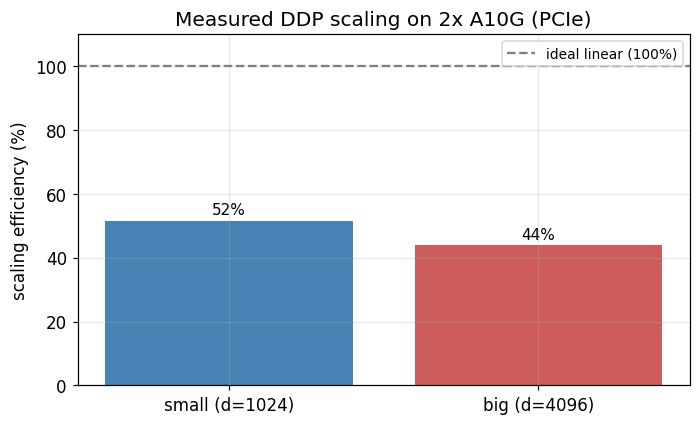

In [8]:
# Measured on 2x A10G (PCIe) via Modal; see results/modal_results_2xa10g.txt.
ddp = {
    "small (d=1024)": {"one_gpu": 11377.87, "two_gpu": 11752.03},
    "big (d=4096)":   {"one_gpu": 1788.94,  "two_gpu": 1570.71},
}
labels, effs = [], []
print(f"{'config':<16}{'1-GPU samp/s':>14}{'2-GPU samp/s':>14}{'efficiency':>12}")
print("-" * 56)
for name, d in ddp.items():
    eff = d["two_gpu"] / (2 * d["one_gpu"]) * 100
    labels.append(name); effs.append(eff)
    print(f"{name:<16}{d['one_gpu']:>14.0f}{d['two_gpu']:>14.0f}{eff:>11.0f}%")

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(labels, effs, color=["steelblue", "indianred"])
ax.axhline(100, ls="--", color="gray", label="ideal linear (100%)")
ax.set_ylabel("scaling efficiency (%)"); ax.set_ylim(0, 110)
ax.set_title("Measured DDP scaling on 2x A10G (PCIe)")
for b, e in zip(bars, effs):
    ax.text(b.get_x() + b.get_width()/2, e + 2, f"{e:.0f}%", ha="center", fontsize=10)
ax.legend(fontsize=9)
plt.show()

## Measured: FSDP peak memory versus the modeled floor

The 16/N bytes-per-parameter figure is a modeled steady-state floor. Real peak
memory sits above it because of transient all-gathers, activations, and allocator
fragmentation. The numbers below were **measured on two A10G GPUs** with a 407M
parameter model under FSDP2 (`fully_shard` + `MixedPrecisionPolicy`), with and
without activation checkpointing. Reproduce with:

```bash
torchrun --standalone --nproc_per_node=2 fsdp_train.py --steps 50 --warmup 15
torchrun --standalone --nproc_per_node=2 fsdp_train.py --steps 50 --warmup 15 --checkpoint
```

The measured peak is about 2.2 times the modeled model-state floor. Activation
checkpointing cuts peak memory by roughly 39% at a cost of about 21% throughput,
because it recomputes activations in the backward pass instead of storing them.
Both the memory saving and the throughput cost are measured, not asserted.

modeled model-state floor (16B/param / 2) = 3.26 GB

config              measured peak GB   gap over floor GB   samples/s
--------------------------------------------------------------------
no checkpoint                   7.10                3.84        85.7
activation ckpt                 4.32                1.07        67.7


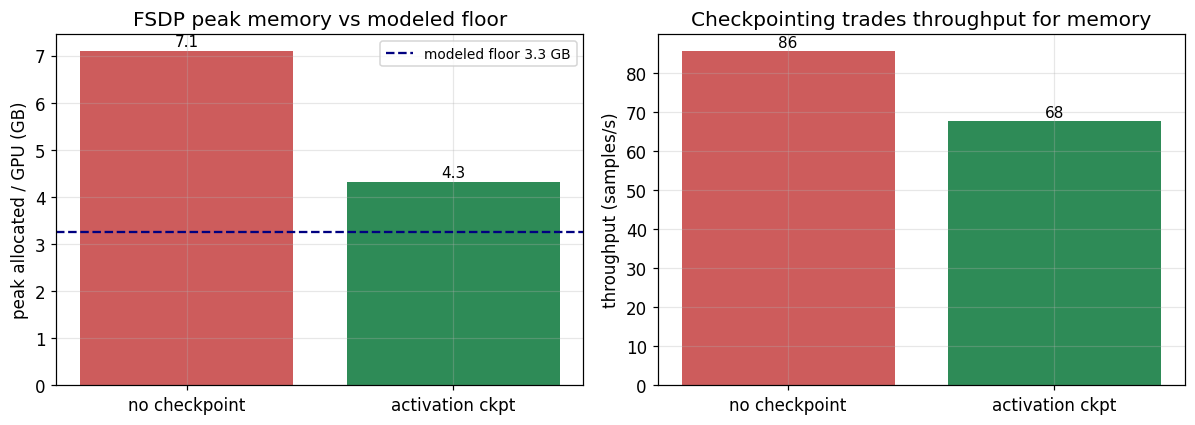


activation checkpointing: peak memory -39%, throughput -21% (measured).


In [9]:
# Measured on 2x A10G via Modal; see results/modal_results_2xa10g.txt. 407M-param model, FSDP2.
modeled_floor = 3.2562
fsdp = {
    "no checkpoint": {"peak_gb": 7.0968, "samples_s": 85.67},
    "activation ckpt": {"peak_gb": 4.3221, "samples_s": 67.71},
}
print(f"modeled model-state floor (16B/param / 2) = {modeled_floor:.2f} GB\n")
print(f"{'config':<18}{'measured peak GB':>18}{'gap over floor GB':>20}{'samples/s':>12}")
print("-" * 68)
for name, d in fsdp.items():
    gap = d["peak_gb"] - modeled_floor
    print(f"{name:<18}{d['peak_gb']:>18.2f}{gap:>20.2f}{d['samples_s']:>12.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
names = list(fsdp)
peaks = [fsdp[n]["peak_gb"] for n in names]
ax1.bar(names, peaks, color=["indianred", "seagreen"])
ax1.axhline(modeled_floor, ls="--", color="navy", label=f"modeled floor {modeled_floor:.1f} GB")
ax1.set_ylabel("peak allocated / GPU (GB)")
ax1.set_title("FSDP peak memory vs modeled floor")
for i, p in enumerate(peaks):
    ax1.text(i, p + 0.1, f"{p:.1f}", ha="center", fontsize=10)
ax1.legend(fontsize=9)

tps = [fsdp[n]["samples_s"] for n in names]
ax2.bar(names, tps, color=["indianred", "seagreen"])
ax2.set_ylabel("throughput (samples/s)")
ax2.set_title("Checkpointing trades throughput for memory")
for i, t in enumerate(tps):
    ax2.text(i, t + 1, f"{t:.0f}", ha="center", fontsize=10)
plt.show()

drop_mem = (1 - fsdp["activation ckpt"]["peak_gb"] / fsdp["no checkpoint"]["peak_gb"]) * 100
drop_tp = (1 - fsdp["activation ckpt"]["samples_s"] / fsdp["no checkpoint"]["samples_s"]) * 100
print(f"\nactivation checkpointing: peak memory -{drop_mem:.0f}%, throughput -{drop_tp:.0f}% (measured).")

## Reproducing the multi-GPU cells

The analytical cells above run anywhere. The two measured sections need at least two
GPUs. Three ways to run them:

1. **A local multi-GPU node**: launch `ddp_train.py` and `fsdp_train.py` with the
   `torchrun` commands shown in each section.
2. **A cloud node**: same commands on any two-GPU (or larger) instance.
3. **Modal**: `modal run modal_run.py` runs the analytics, the DDP scaling study,
   and the FSDP memory study on a two-GPU container and writes the results to
   `modal_results.txt`. The numbers embedded above came from `modal run
   modal_run.py::gpu_only` on 2x A10G.

Every strategy in the chapter comes back to one measured fact: the interconnect,
not the Python, sets how well training scales. The small-model DDP result and the
FSDP peak-versus-floor gap are the two places you can see that most directly.